# Supplementary Figure S5 — plotting


In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path(os.environ.get("MITOXY_PROJECT_ROOT","/scratch/ar58064/mitoxy")).resolve()
BLUE="#087EBD"; ORANGE="#E36A00"; TEAL="#00A67E"; PURPLE="#8053A6"
DARK="#202832"; MID="#667386"; GRID="#DDE3E9"; BAND="#F2F5F8"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelcolor":DARK,
 "xtick.color":MID,"ytick.color":DARK,"axes.edgecolor":"#AEB8C4","axes.spines.top":False,
 "axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})

def panel_letter(ax,letter):
    ax.text(-.14,1.08,letter,transform=ax.transAxes,fontsize=21,fontweight="bold",color=DARK,va="top")

def band_rows(ax,n):
    for i in range(n):
        if i%2==0: ax.axhspan(i-.5,i+.5,color=BAND,zorder=0)

def p_text(p): return "P < 1e-4" if p < 1e-4 else f"P = {p:.3f}"

def stat_box(ax,x,y,text,color):
    ax.text(x,y,text,transform=ax.transAxes,ha="left",va="center",fontsize=8.3,fontweight="bold",color=color,
            bbox=dict(boxstyle="round,pad=.26",facecolor="white",edgecolor=color,alpha=.95,linewidth=1))

def save_all(fig,stem,folder):
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ["png","pdf","svg"]:
        fig.savefig(folder/f"{stem}.{ext}",dpi=320 if ext=="png" else None,bbox_inches="tight")

DATA_DIR=PROJECT_ROOT/"data"/"processed"/"supplementary_figure_s5"; FIGURE_DIR=PROJECT_ROOT/"figures"/"supplementary_figure_s5"
data=pd.read_csv(DATA_DIR/"panel_a_paired_data.csv"); summary=pd.read_csv(DATA_DIR/"panel_a_summary.csv")


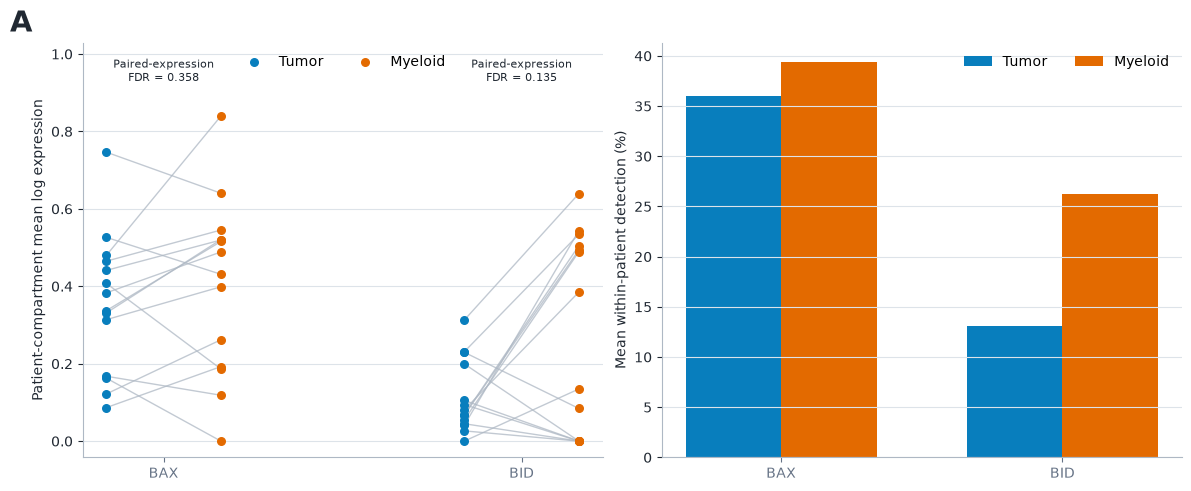

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11.8,4.8),constrained_layout=True)
ax=axes[0]; positions={"BAX":0,"BID":1}; offsets={"Tumor":-.16,"Myeloid":.16}; colors={"Tumor":BLUE,"Myeloid":ORANGE}
for gene in ["BAX","BID"]:
    sub=data.loc[data.gene.eq(gene)]
    wide=sub.pivot(index="patient",columns="compartment",values="mean_log_expression").dropna()
    for _,row in wide.iterrows():
        ax.plot([positions[gene]+offsets["Tumor"],positions[gene]+offsets["Myeloid"]],[row.Tumor,row.Myeloid],color="#AEB8C4",lw=1,alpha=.75)
    for compartment in ["Tumor","Myeloid"]:
        vals=wide[compartment]
        ax.scatter(np.full(len(vals),positions[gene]+offsets[compartment]),vals,color=colors[compartment],s=30,zorder=3,
                   label=compartment if gene=="BAX" else None)
ax.set_xticks([0,1],["BAX","BID"]); ax.set_ylabel("Patient-compartment mean log expression"); ax.grid(axis="y",color=GRID)
ax.legend(frameon=False,ncol=2,loc="upper center")
lower,upper=ax.get_ylim(); span=upper-lower; ax.set_ylim(lower,upper+0.16*span)
for gene in ["BAX","BID"]:
    fdr=float(summary.loc[summary.gene.eq(gene),"paired_fdr"].iloc[0])
    ax.text(positions[gene],upper+0.08*span,f"Paired-expression\nFDR = {fdr:.3f}",ha="center",va="center",fontsize=8,color=DARK)
ax.set_title("",loc="left",fontweight="bold"); panel_letter(ax,"A")

ax=axes[1]; x=np.arange(len(summary)); width=.34
ax.bar(x-width/2,summary.tumor_detection_pct,width,color=BLUE,label="Tumor")
ax.bar(x+width/2,summary.myeloid_detection_pct,width,color=ORANGE,label="Myeloid")
ax.set_xticks(x,summary.gene); ax.set_ylabel("Mean within-patient detection (%)"); ax.grid(axis="y",color=GRID)
ax.legend(frameon=False,ncol=2); ax.set_title("",loc="left",fontweight="bold")
save_all(fig,"Supplementary_Figure_S5",FIGURE_DIR); plt.show()
